Meter-data header found on row 8

=== METER DATA CHECK ===
Site: BU0025 - Lanzai, Dambam LGA Bauchi
First reading: 2026-09-08 14:00:00+00:00
Last reading: 2026-09-15 13:00:00+00:00
Monitoring duration: 167.0 hours
Total consumption: 304.82 kWh
Intervals longer than one hour: 7
Intervals above the stated peak load: 0
Negative meter changes: 0

=== LOAD RECONSTRUCTION CHECK ===
Meter difference: 304.82 kWh
Reconstructed load: 304.82 kWh
Difference: 0.0000 kWh
Hours estimated across gaps: 118

=== RENEWABLES.NINJA CHECK ===
count    8760.000000
mean        0.191224
std         0.252806
min         0.000000
25%         0.000000
50%         0.000000
75%         0.401000
max         0.805000
Name: electricity, dtype: float64

Using Renewables.ninja year: 2025

=== DATA ALIGNMENT CHECK ===
Meter hours: 168
Matched solar hours: 168
Hours without solar data: 0

=== BATTERY WARM-UP ===
Warm-up cycles: 2
Stabilised starting SOC: 95.0%

MASKH BU0025 – ENERGY RESULTS
Period: 2026-09-08 15:00:00+00:

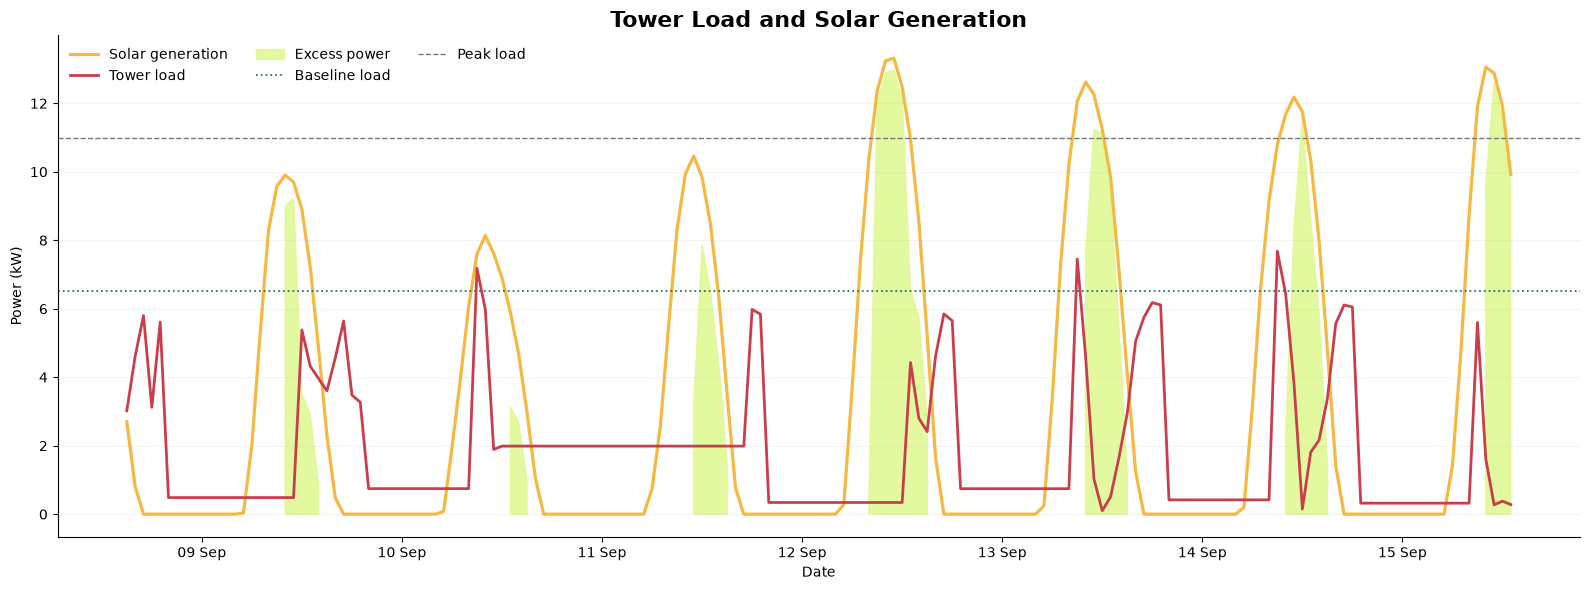

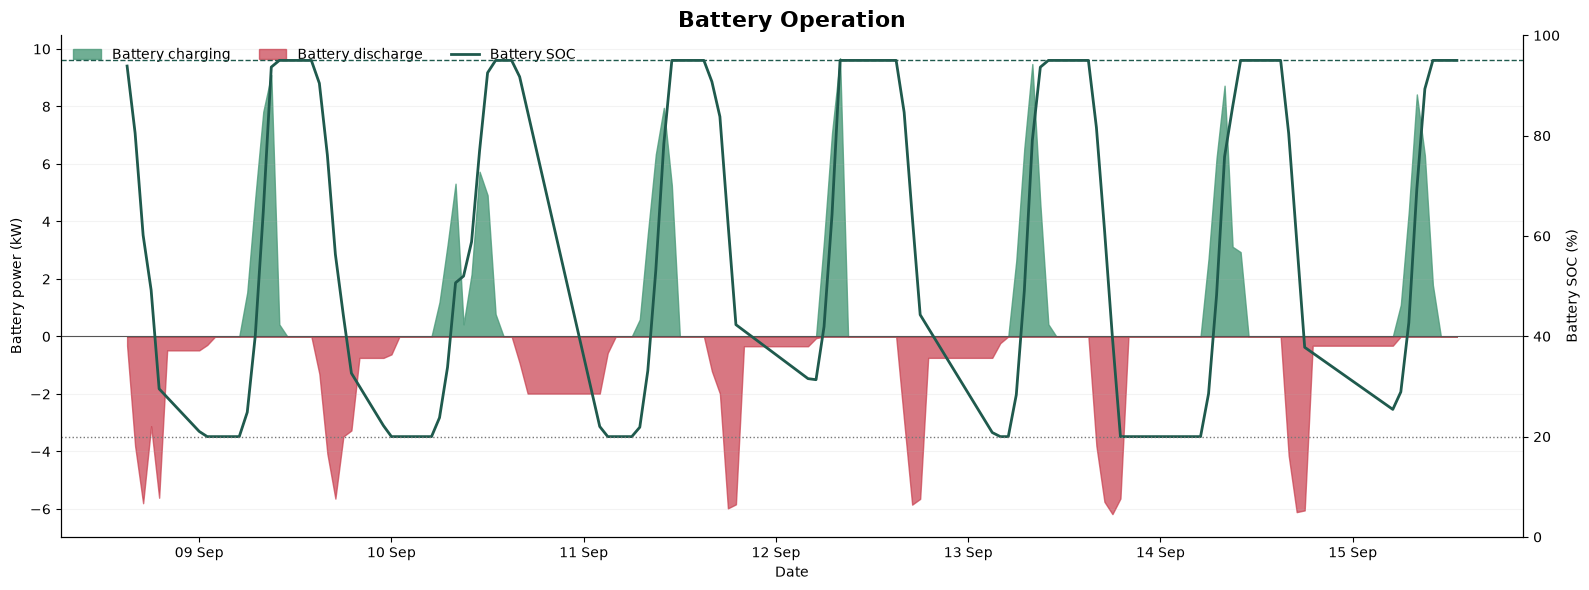

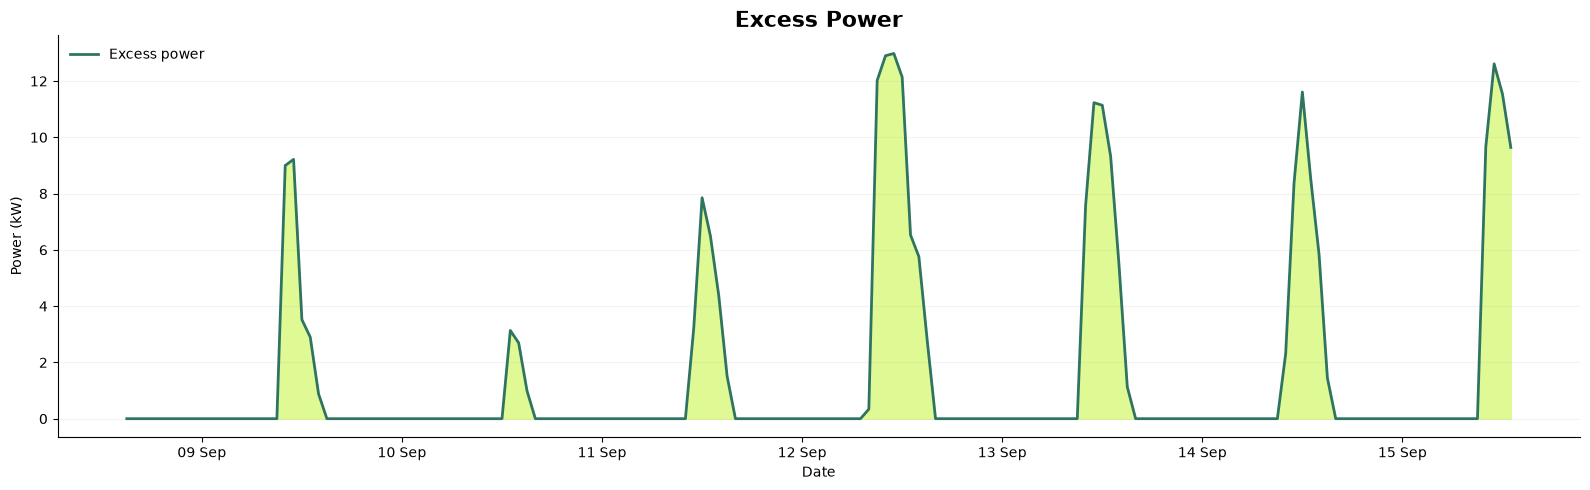

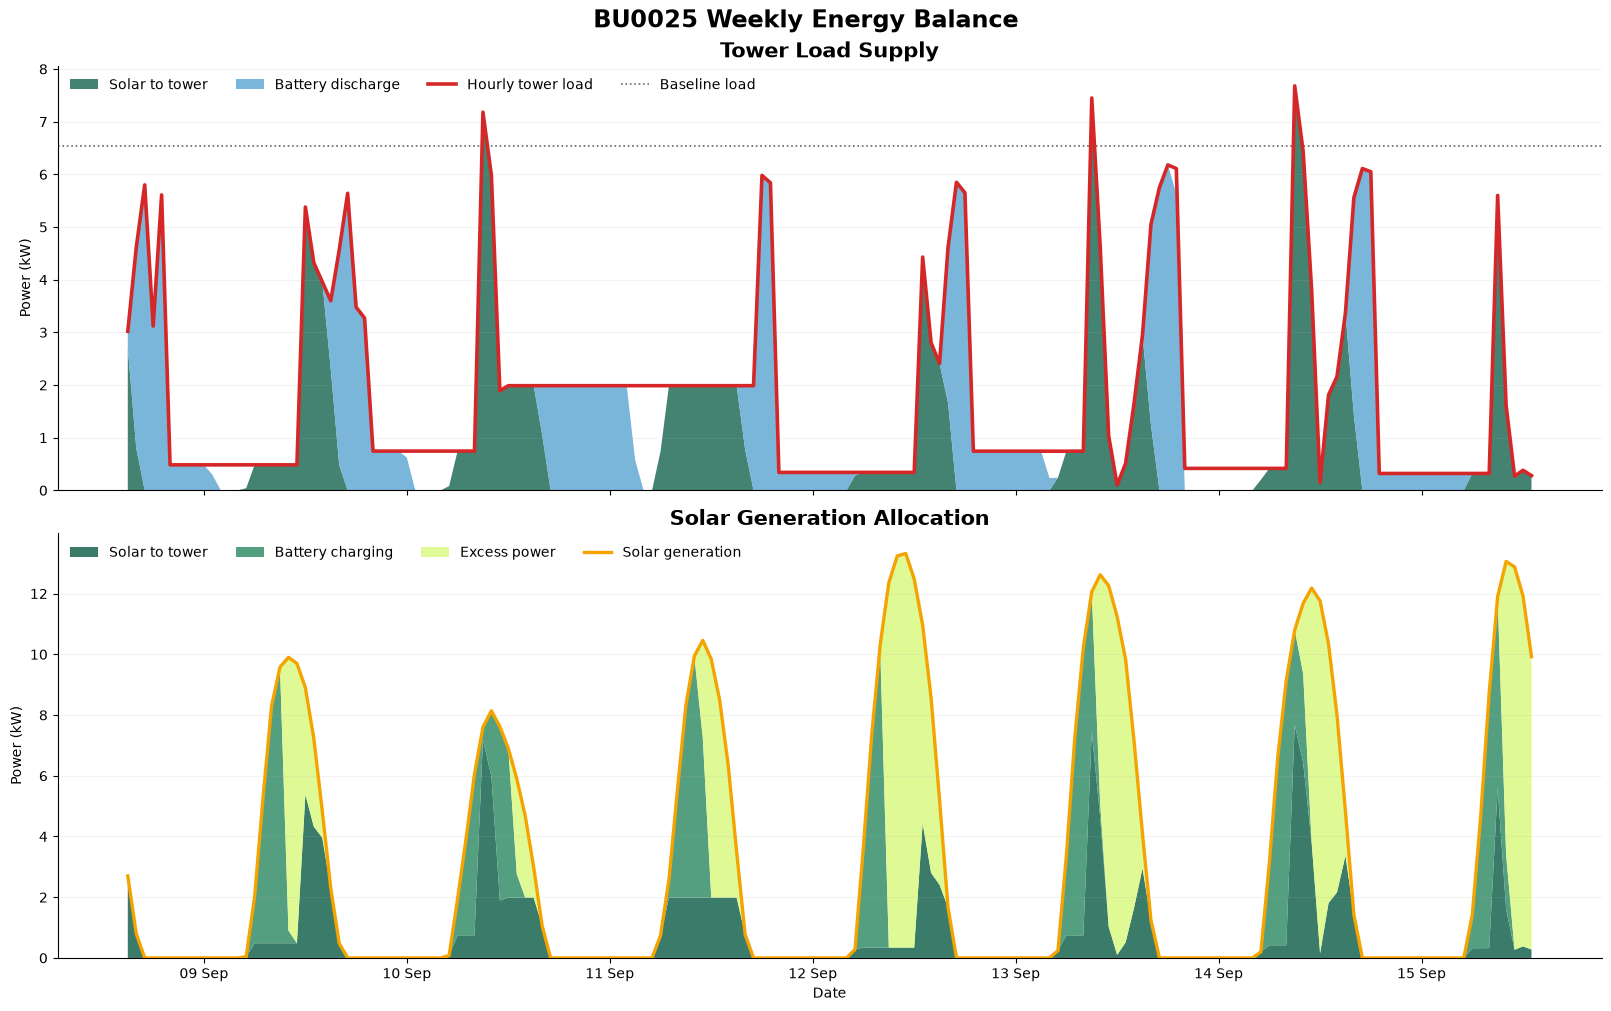

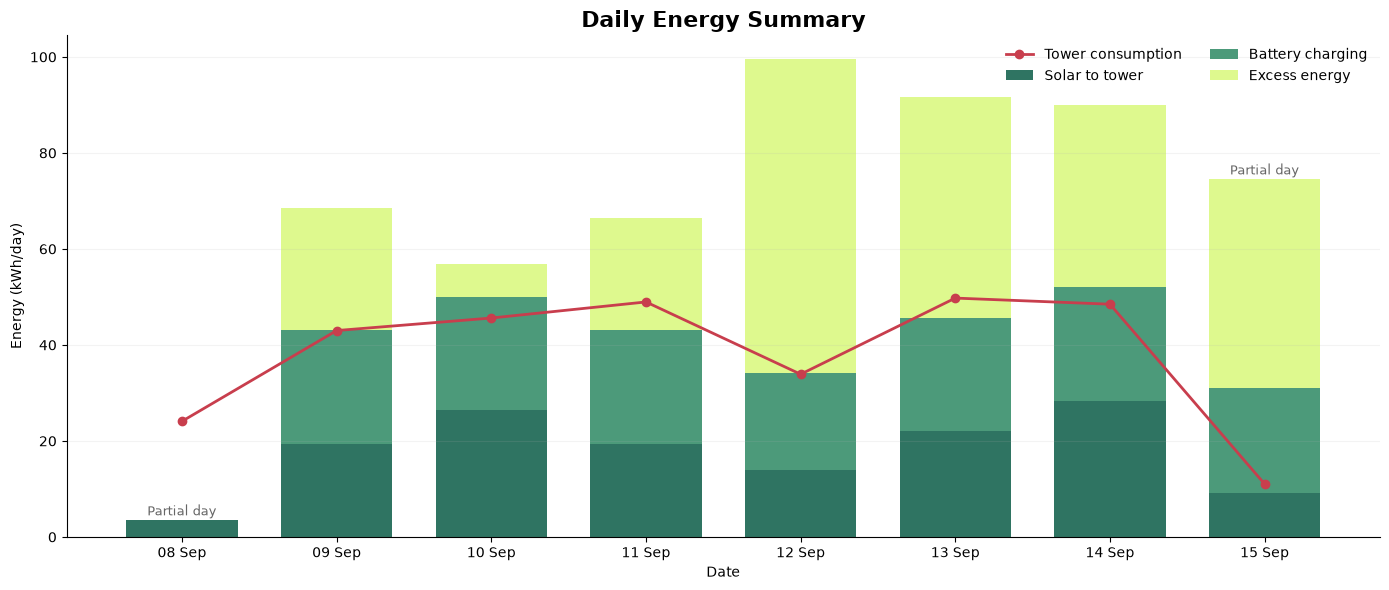


Exported files:
1. maskh_BU0025_hourly_energy_analysis.csv
2. maskh_BU0025_daily_summary.csv
3. maskh_BU0025_meter_quality_check.csv
4. maskh_BU0025_battery_assumptions.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# =========================================================
# MASKH BU0025 – SOLAR EXCESS POWER ASSESSMENT
# =========================================================

SITE_ID = "BU0025"
SITE_NAME = "Lanzai, Dambam LGA Bauchi"

PV_CAPACITY_KW = 20
BESS_CAPACITY_KWH = 30
INVERTER_CAPACITY_KW = 22
BASELINE_LOAD_KW = 6.53
PEAK_LOAD_KW = 11

METER_FILE = "maskh_BU0025_meter.csv"
NINJA_FILE = "ninja_BU0025.csv"

# True if Ninja electricity is normalised between 0 and 1.
NINJA_IS_CAPACITY_FACTOR = True

# Leave as None if the Ninja file contains only one year.
SELECTED_NINJA_YEAR = None

# =========================================================
# BATTERY ASSUMPTIONS
# =========================================================

BATTERY_MAX_SOC = 0.95
BATTERY_MIN_SOC = 0.2

BATTERY_CHARGE_EFFICIENCY = 0.95
BATTERY_DISCHARGE_EFFICIENCY = 0.95

# Assumed 0.5C charge/discharge rate.
BATTERY_MAX_CHARGE_KW = 15
BATTERY_MAX_DISCHARGE_KW = 15

BATTERY_MAX_ENERGY_KWH = (
    BESS_CAPACITY_KWH * BATTERY_MAX_SOC
)

BATTERY_MIN_ENERGY_KWH = (
    BESS_CAPACITY_KWH * BATTERY_MIN_SOC
)

# Number of times the available period is repeated so that the
# initial battery condition does not distort the reported period.
MAX_WARMUP_CYCLES = 30
SOC_CONVERGENCE_TOLERANCE_KWH = 0.001

# =========================================================
# 1. LOAD MASKH METER DATA
# =========================================================

raw_df = pd.read_csv(
    METER_FILE,
    header=None,
    sep=None,
    engine="python"
)

timestamp_rows = raw_df.apply(
    lambda row: row.astype(str)
    .str.strip()
    .str.lower()
    .eq("timestamp")
    .any(),
    axis=1
)

if not timestamp_rows.any():
    raise ValueError(
        "No row labelled 'Timestamp' was found."
    )

header_row = timestamp_rows[timestamp_rows].index[0]

print(f"Meter-data header found on row {header_row + 1}")

meter_df = pd.read_csv(
    METER_FILE,
    skiprows=header_row,
    sep=None,
    engine="python"
)

meter_df.columns = (
    meter_df.columns
    .astype(str)
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

meter_df = meter_df.rename(columns={
    "Timestamp": "time",
    "Meter Reading (kWh)": "cumulative_kwh",
    "Usage Amount (kWh)": "reported_usage_kwh"
})

required_columns = ["time", "cumulative_kwh"]

missing_columns = [
    column for column in required_columns
    if column not in meter_df.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns missing: {missing_columns}. "
        f"Detected columns: {meter_df.columns.tolist()}"
    )

meter_df["time"] = pd.to_datetime(
    meter_df["time"],
    utc=True,
    errors="coerce"
)

meter_df["cumulative_kwh"] = pd.to_numeric(
    meter_df["cumulative_kwh"],
    errors="coerce"
)

if "reported_usage_kwh" in meter_df.columns:

    meter_df["reported_usage_kwh"] = pd.to_numeric(
        meter_df["reported_usage_kwh"],
        errors="coerce"
    )

else:

    meter_df["reported_usage_kwh"] = np.nan

meter_df = (
    meter_df
    .dropna(subset=["time", "cumulative_kwh"])
    .sort_values("time")
    .reset_index(drop=True)
)

if meter_df.empty:
    raise ValueError("No valid meter readings remain.")

# =========================================================
# 2. ALIGN METER TIMESTAMPS TO COMPLETE HOURS
# =========================================================

meter_df["original_time"] = meter_df["time"]

# Required because timestamps contain varying seconds.
meter_df["time"] = meter_df["time"].dt.round("h")

meter_df = (
    meter_df
    .sort_values("original_time")
    .drop_duplicates(subset="time", keep="last")
    .sort_values("time")
    .reset_index(drop=True)
)

# =========================================================
# 3. CHECK ORIGINAL METER INTERVALS
# =========================================================

meter_df["interval_hours"] = (
    meter_df["time"].diff().dt.total_seconds() / 3600
)

meter_df["calculated_interval_kwh"] = (
    meter_df["cumulative_kwh"].diff()
)

meter_df["interval_average_kw"] = (
    meter_df["calculated_interval_kwh"]
    / meter_df["interval_hours"]
)

meter_df["missing_hours_before_reading"] = (
    meter_df["interval_hours"] - 1
).clip(lower=0)

meter_df["above_peak_load_flag"] = (
    meter_df["interval_average_kw"] > PEAK_LOAD_KW
)

meter_df["negative_meter_change_flag"] = (
    meter_df["calculated_interval_kwh"] < 0
)

source_total_kwh = (
    meter_df["cumulative_kwh"].iloc[-1]
    - meter_df["cumulative_kwh"].iloc[0]
)

monitoring_hours = (
    meter_df["time"].iloc[-1]
    - meter_df["time"].iloc[0]
).total_seconds() / 3600

print("\n=== METER DATA CHECK ===")
print("Site:", SITE_ID, "-", SITE_NAME)
print("First reading:", meter_df["time"].min())
print("Last reading:", meter_df["time"].max())
print(f"Monitoring duration: {monitoring_hours:,.1f} hours")
print(f"Total consumption: {source_total_kwh:,.2f} kWh")

print(
    "Intervals longer than one hour:",
    int((meter_df["interval_hours"] > 1.1).sum())
)

print(
    "Intervals above the stated peak load:",
    int(meter_df["above_peak_load_flag"].sum())
)

print(
    "Negative meter changes:",
    int(meter_df["negative_meter_change_flag"].sum())
)

# =========================================================
# 4. RECONSTRUCT HOURLY TOWER LOAD
# =========================================================

hourly_index = pd.date_range(
    start=meter_df["time"].min(),
    end=meter_df["time"].max(),
    freq="1h",
    tz="UTC"
)

meter_hourly = (
    meter_df[["time", "cumulative_kwh"]]
    .set_index("time")
    .reindex(hourly_index)
)

meter_hourly.index.name = "time"

meter_hourly["observed_meter_reading"] = (
    meter_hourly["cumulative_kwh"].notna()
)

# Distribute the meter difference evenly across missing hours.
meter_hourly["cumulative_kwh"] = (
    meter_hourly["cumulative_kwh"]
    .interpolate(method="time", limit_area="inside")
)

meter_hourly["load_kwh"] = (
    meter_hourly["cumulative_kwh"].diff()
)

# For a one-hour interval, kWh is numerically equal to average kW.
meter_hourly["load_kw"] = meter_hourly["load_kwh"]

meter_hourly["estimated_from_gap"] = ~(
    meter_hourly["observed_meter_reading"]
    & meter_hourly["observed_meter_reading"]
    .shift(1)
    .fillna(False)
)

# Remove impossible negative consumption.
meter_hourly.loc[
    meter_hourly["load_kw"] < 0,
    ["load_kw", "load_kwh"]
] = np.nan

meter_hourly = meter_hourly.reset_index()

reconstructed_total_kwh = meter_hourly["load_kwh"].sum()

print("\n=== LOAD RECONSTRUCTION CHECK ===")
print(f"Meter difference: {source_total_kwh:,.2f} kWh")
print(f"Reconstructed load: {reconstructed_total_kwh:,.2f} kWh")

print(
    f"Difference: "
    f"{reconstructed_total_kwh - source_total_kwh:,.4f} kWh"
)

print(
    "Hours estimated across gaps:",
    int(meter_hourly["estimated_from_gap"].sum())
)

# =========================================================
# 5. LOAD RENEWABLES.NINJA DATA
# =========================================================

ninja_df = pd.read_csv(
    NINJA_FILE,
    comment="#",
    sep=None,
    engine="python"
)

ninja_df.columns = (
    ninja_df.columns
    .astype(str)
    .str.strip()
)

required_ninja_columns = ["time", "electricity"]

missing_ninja_columns = [
    column for column in required_ninja_columns
    if column not in ninja_df.columns
]

if missing_ninja_columns:
    raise ValueError(
        f"Ninja columns missing: {missing_ninja_columns}. "
        f"Detected columns: {ninja_df.columns.tolist()}"
    )

ninja_df["time"] = pd.to_datetime(
    ninja_df["time"],
    utc=True,
    errors="coerce"
)

ninja_df["electricity"] = pd.to_numeric(
    ninja_df["electricity"],
    errors="coerce"
)

ninja_df = (
    ninja_df
    .dropna(subset=["time", "electricity"])
    .sort_values("time")
    .reset_index(drop=True)
)

if ninja_df.empty:
    raise ValueError(
        "No valid Renewables.ninja data were found."
    )

print("\n=== RENEWABLES.NINJA CHECK ===")
print(ninja_df["electricity"].describe())

if (
    NINJA_IS_CAPACITY_FACTOR
    and ninja_df["electricity"].max() > 1.05
):
    raise ValueError(
        "The Ninja output exceeds 1.05. It may already be "
        "expressed in kW. Change NINJA_IS_CAPACITY_FACTOR "
        "to False and run the code again."
    )

# =========================================================
# 6. SCALE PV GENERATION
# =========================================================

if NINJA_IS_CAPACITY_FACTOR:

    ninja_df["solar_generation_kw"] = (
        ninja_df["electricity"] * PV_CAPACITY_KW
    )

else:

    ninja_df["solar_generation_kw"] = (
        ninja_df["electricity"]
    )

maximum_solar_output_kw = min(
    PV_CAPACITY_KW,
    INVERTER_CAPACITY_KW
)

ninja_df["solar_generation_kw"] = (
    ninja_df["solar_generation_kw"]
    .clip(lower=0, upper=maximum_solar_output_kw)
)

# =========================================================
# 7. SELECT AND ALIGN THE NINJA YEAR
# =========================================================

available_ninja_years = sorted(
    ninja_df["time"].dt.year.unique()
)

if SELECTED_NINJA_YEAR is None:
    SELECTED_NINJA_YEAR = available_ninja_years[0]

if SELECTED_NINJA_YEAR not in available_ninja_years:
    raise ValueError(
        f"Ninja year {SELECTED_NINJA_YEAR} is unavailable. "
        f"Available years: {available_ninja_years}"
    )

ninja_df = ninja_df[
    ninja_df["time"].dt.year == SELECTED_NINJA_YEAR
].copy()

print(
    f"\nUsing Renewables.ninja year: "
    f"{SELECTED_NINJA_YEAR}"
)

# Match month, day and UTC hour.
meter_hourly["profile_key"] = (
    meter_hourly["time"].dt.strftime("%m-%d %H")
)

ninja_df["profile_key"] = (
    ninja_df["time"].dt.strftime("%m-%d %H")
)

ninja_profile = (
    ninja_df[["profile_key", "solar_generation_kw"]]
    .drop_duplicates(subset="profile_key", keep="first")
)

merged = pd.merge(
    meter_hourly,
    ninja_profile,
    on="profile_key",
    how="left"
)

merged = (
    merged
    .sort_values("time")
    .reset_index(drop=True)
)

missing_solar_hours = (
    merged["solar_generation_kw"].isna().sum()
)

print("\n=== DATA ALIGNMENT CHECK ===")
print("Meter hours:", len(meter_hourly))

print(
    "Matched solar hours:",
    merged["solar_generation_kw"].notna().sum()
)

print(
    "Hours without solar data:",
    missing_solar_hours
)

analysis = merged.dropna(
    subset=["load_kw", "solar_generation_kw"]
).copy()

if analysis.empty:
    raise ValueError(
        "The merged dataset is empty. Check the dates and "
        "timestamps in both files."
    )

# =========================================================
# 8. BATTERY DISPATCH FUNCTION
# =========================================================

def simulate_battery(data, initial_battery_kwh):

    battery_kwh = float(initial_battery_kwh)

    records = []

    for _, row in data.iterrows():

        solar_kw = max(float(row["solar_generation_kw"]), 0)
        load_kw = max(float(row["load_kw"]), 0)

        solar_to_tower_kw = min(solar_kw, load_kw)

        solar_remaining_kw = max(
            solar_kw - solar_to_tower_kw,
            0
        )

        load_remaining_kw = max(
            load_kw - solar_to_tower_kw,
            0
        )

        battery_charging_kw = 0
        battery_discharge_kw = 0
        other_supply_kw = 0
        excess_power_kw = 0
        charging_limit_loss_kw = 0

        # -------------------------------------------------
        # SURPLUS SOLAR: CHARGE BATTERY FIRST
        # -------------------------------------------------

        if solar_remaining_kw > 0:

            battery_headroom_kwh = max(
                BATTERY_MAX_ENERGY_KWH - battery_kwh,
                0
            )

            maximum_charge_input_kw = (
                battery_headroom_kwh
                / BATTERY_CHARGE_EFFICIENCY
            )

            battery_charging_kw = min(
                solar_remaining_kw,
                BATTERY_MAX_CHARGE_KW,
                maximum_charge_input_kw
            )

            battery_kwh += (
                battery_charging_kw
                * BATTERY_CHARGE_EFFICIENCY
            )

            # Correct very small floating-point deviations.
            battery_kwh = min(
                battery_kwh,
                BATTERY_MAX_ENERGY_KWH
            )

            solar_after_charging_kw = max(
                solar_remaining_kw
                - battery_charging_kw,
                0
            )

            battery_full = (
                battery_kwh
                >= BATTERY_MAX_ENERGY_KWH - 1e-6
            )

            # Count solar as excess only when the battery is full.
            if battery_full:
                excess_power_kw = solar_after_charging_kw
            else:
                charging_limit_loss_kw = solar_after_charging_kw

        # -------------------------------------------------
        # SOLAR DEFICIT: BATTERY SUPPLIES TOWER
        # -------------------------------------------------

        elif load_remaining_kw > 0:

            battery_available_kwh = max(
                battery_kwh - BATTERY_MIN_ENERGY_KWH,
                0
            )

            maximum_delivered_from_battery_kw = (
                battery_available_kwh
                * BATTERY_DISCHARGE_EFFICIENCY
            )

            battery_discharge_kw = min(
                load_remaining_kw,
                BATTERY_MAX_DISCHARGE_KW,
                maximum_delivered_from_battery_kw
            )

            battery_kwh -= (
                battery_discharge_kw
                / BATTERY_DISCHARGE_EFFICIENCY
            )

            battery_kwh = max(
                battery_kwh,
                BATTERY_MIN_ENERGY_KWH
            )

            other_supply_kw = max(
                load_remaining_kw
                - battery_discharge_kw,
                0
            )

        battery_soc_percent = (
            100 * battery_kwh / BESS_CAPACITY_KWH
        )

        records.append({
            "solar_to_tower_kw": solar_to_tower_kw,
            "battery_charging_kw": battery_charging_kw,
            "battery_discharge_kw": battery_discharge_kw,
            "other_supply_kw": other_supply_kw,
            "excess_power_kw": excess_power_kw,
            "charging_limit_loss_kw": charging_limit_loss_kw,
            "battery_energy_kwh": battery_kwh,
            "battery_soc_percent": battery_soc_percent
        })

    results = pd.DataFrame(
        records,
        index=data.index
    )

    return results, battery_kwh

# =========================================================
# 9. BATTERY WARM-UP
# =========================================================

# Start at 50% SOC only for the warm-up calculation.
initial_battery_kwh = 0.50 * BESS_CAPACITY_KWH

initial_battery_kwh = np.clip(
    initial_battery_kwh,
    BATTERY_MIN_ENERGY_KWH,
    BATTERY_MAX_ENERGY_KWH
)

completed_cycles = 0

for cycle in range(MAX_WARMUP_CYCLES):

    _, ending_battery_kwh = simulate_battery(
        analysis,
        initial_battery_kwh
    )

    completed_cycles = cycle + 1

    if (
        abs(ending_battery_kwh - initial_battery_kwh)
        <= SOC_CONVERGENCE_TOLERANCE_KWH
    ):
        break

    initial_battery_kwh = ending_battery_kwh

print("\n=== BATTERY WARM-UP ===")
print("Warm-up cycles:", completed_cycles)

print(
    f"Stabilised starting SOC: "
    f"{100 * initial_battery_kwh / BESS_CAPACITY_KWH:,.1f}%"
)

# Run the reported period using the stabilised initial condition.
battery_results, final_battery_kwh = simulate_battery(
    analysis,
    initial_battery_kwh
)

analysis = pd.concat(
    [analysis, battery_results],
    axis=1
)

# =========================================================
# 10. CONVERT HOURLY POWER TO ENERGY
# =========================================================

# Each interval is one hour, so kW × 1 hour = kWh.
energy_columns = {
    "solar_generation_kw": "solar_generation_kwh",
    "load_kw": "tower_load_kwh",
    "solar_to_tower_kw": "solar_to_tower_kwh",
    "battery_charging_kw": "battery_charging_kwh",
    "battery_discharge_kw": "battery_discharge_kwh",
    "other_supply_kw": "other_supply_kwh",
    "excess_power_kw": "excess_energy_kwh",
    "charging_limit_loss_kw": "charging_limit_loss_kwh"
}

for power_column, energy_column in energy_columns.items():
    analysis[energy_column] = analysis[power_column]

# =========================================================
# 11. SUMMARY METRICS
# =========================================================

total_solar_kwh = analysis["solar_generation_kwh"].sum()
total_load_kwh = analysis["tower_load_kwh"].sum()
total_solar_to_tower_kwh = analysis["solar_to_tower_kwh"].sum()
total_battery_charge_kwh = analysis["battery_charging_kwh"].sum()
total_battery_discharge_kwh = analysis["battery_discharge_kwh"].sum()
total_other_supply_kwh = analysis["other_supply_kwh"].sum()
total_excess_kwh = analysis["excess_energy_kwh"].sum()

solar_utilisation_kwh = (
    total_solar_to_tower_kwh
    + total_battery_charge_kwh
)

solar_utilisation_rate = (
    100 * solar_utilisation_kwh / total_solar_kwh
    if total_solar_kwh > 0
    else np.nan
)

excess_rate = (
    100 * total_excess_kwh / total_solar_kwh
    if total_solar_kwh > 0
    else np.nan
)

hours_with_excess = (
    analysis["excess_power_kw"] > 0
).sum()

print("\n==============================================")
print("MASKH BU0025 – ENERGY RESULTS")
print("==============================================")

print(
    f"Period: {analysis['time'].min()} "
    f"to {analysis['time'].max()}"
)

print(f"Solar generation: {total_solar_kwh:,.2f} kWh")
print(f"Tower consumption: {total_load_kwh:,.2f} kWh")
print(f"Solar to tower: {total_solar_to_tower_kwh:,.2f} kWh")
print(f"Battery charging: {total_battery_charge_kwh:,.2f} kWh")
print(f"Battery discharge: {total_battery_discharge_kwh:,.2f} kWh")
print(f"Other supply: {total_other_supply_kwh:,.2f} kWh")
print(f"Excess energy: {total_excess_kwh:,.2f} kWh")
print(f"Hours with excess power: {hours_with_excess}")
print(f"Solar utilisation rate: {solar_utilisation_rate:,.1f}%")
print(f"Excess rate: {excess_rate:,.1f}%")

print(
    f"Starting battery SOC: "
    f"{100 * initial_battery_kwh / BESS_CAPACITY_KWH:,.1f}%"
)

print(
    f"Ending battery SOC: "
    f"{100 * final_battery_kwh / BESS_CAPACITY_KWH:,.1f}%"
)

print("==============================================")

# =========================================================
# 12. PLOT 1 – TOWER LOAD AND SOLAR GENERATION
# =========================================================

fig, ax = plt.subplots(figsize=(16, 6))

ax.plot(
    analysis["time"],
    analysis["solar_generation_kw"],
    color="#F4B942",
    linewidth=2.3,
    label="Solar generation"
)

ax.plot(
    analysis["time"],
    analysis["load_kw"],
    color="#C83E4D",
    linewidth=2,
    label="Tower load"
)

ax.fill_between(
    analysis["time"],
    0,
    analysis["excess_power_kw"],
    where=analysis["excess_power_kw"] > 0,
    color="#DEF98E",
    alpha=0.85,
    label="Excess power"
)

ax.axhline(
    BASELINE_LOAD_KW,
    color="#2F7462",
    linestyle=":",
    linewidth=1.3,
    label="Baseline load"
)

ax.axhline(
    PEAK_LOAD_KW,
    color="#777777",
    linestyle="--",
    linewidth=1,
    label="Peak load"
)

ax.set_title(
    "Tower Load and Solar Generation",
    fontsize=16,
    fontweight="bold"
)

ax.set_xlabel("Date")
ax.set_ylabel("Power (kW)")

ax.xaxis.set_major_locator(mdates.DayLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))

ax.legend(
    loc="upper left",
    frameon=False,
    ncol=3
)

ax.grid(axis="y", alpha=0.15)

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

# =========================================================
# 13. PLOT 2 – BATTERY OPERATION
# =========================================================

fig, ax1 = plt.subplots(figsize=(16, 6))

ax1.fill_between(
    analysis["time"],
    0,
    analysis["battery_charging_kw"],
    color="#4C9A7A",
    alpha=0.80,
    label="Battery charging"
)

ax1.fill_between(
    analysis["time"],
    0,
    -analysis["battery_discharge_kw"],
    color="#C83E4D",
    alpha=0.70,
    label="Battery discharge"
)

ax1.axhline(
    0,
    color="#555555",
    linewidth=0.8
)

ax1.set_xlabel("Date")
ax1.set_ylabel("Battery power (kW)")

ax1.xaxis.set_major_locator(mdates.DayLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))

ax2 = ax1.twinx()

ax2.plot(
    analysis["time"],
    analysis["battery_soc_percent"],
    color="#1F5A4D",
    linewidth=2,
    label="Battery SOC"
)

ax2.axhline(
    BATTERY_MAX_SOC * 100,
    color="#1F5A4D",
    linestyle="--",
    linewidth=1
)

ax2.axhline(
    BATTERY_MIN_SOC * 100,
    color="#777777",
    linestyle=":",
    linewidth=1
)

ax2.set_ylabel("Battery SOC (%)")
ax2.set_ylim(0, 100)

lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines_1 + lines_2,
    labels_1 + labels_2,
    loc="upper left",
    frameon=False,
    ncol=3
)

ax1.set_title(
    "Battery Operation",
    fontsize=16,
    fontweight="bold"
)

ax1.grid(axis="y", alpha=0.15)

for spine in ["top"]:
    ax1.spines[spine].set_visible(False)
    ax2.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

# =========================================================
# 14. PLOT 3 – EXCESS POWER
# =========================================================

fig, ax = plt.subplots(figsize=(16, 5))

ax.fill_between(
    analysis["time"],
    0,
    analysis["excess_power_kw"],
    color="#DEF98E",
    alpha=0.95
)

ax.plot(
    analysis["time"],
    analysis["excess_power_kw"],
    color="#2F7462",
    linewidth=2,
    label="Excess power"
)

ax.set_title(
    "Excess Power",
    fontsize=16,
    fontweight="bold"
)

ax.set_xlabel("Date")
ax.set_ylabel("Power (kW)")

ax.xaxis.set_major_locator(mdates.DayLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))

ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.15)

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

# =========================================================
# 15. PLOT 4 – WEEKLY ENERGY BALANCE STREAMGRAPH
# =========================================================

# =========================================================
# WEEKLY ENERGY BALANCE
# =========================================================

fig, (ax1, ax2) = plt.subplots(
    2,
    1,
    figsize=(16, 10),
    sharex=True,
    gridspec_kw={"height_ratios": [1, 1]},
    constrained_layout=True
)

# ---------------------------------------------------------
# PANEL 1 – HOW THE TOWER LOAD IS SUPPLIED
# ---------------------------------------------------------

ax1.stackplot(
    analysis["time"],
    analysis["solar_to_tower_kw"],
    analysis["battery_discharge_kw"],
    labels=[
        "Solar to tower",
        "Battery discharge"
    ],
    colors=[
        "#2F7462",
        "#6BAED6"
    ],
    alpha=0.90
)

ax1.plot(
    analysis["time"],
    analysis["load_kw"],
    color="#D62728",
    linewidth=2.6,
    label="Hourly tower load",
    zorder=5
)

ax1.axhline(
    BASELINE_LOAD_KW,
    color="#666666",
    linestyle=":",
    linewidth=1.2,
    label="Baseline load"
)

ax1.set_title(
    "Tower Load Supply",
    fontsize=15,
    fontweight="bold"
)

ax1.set_ylabel("Power (kW)")

ax1.legend(
    loc="upper left",
    frameon=False,
    ncol=4
)

ax1.grid(axis="y", alpha=0.15)

for spine in ["top", "right"]:
    ax1.spines[spine].set_visible(False)

# ---------------------------------------------------------
# PANEL 2 – HOW SOLAR GENERATION IS USED
# ---------------------------------------------------------

ax2.stackplot(
    analysis["time"],
    analysis["solar_to_tower_kw"],
    analysis["battery_charging_kw"],
    analysis["excess_power_kw"],
    labels=[
        "Solar to tower",
        "Battery charging",
        "Excess power"
    ],
    colors=[
        "#2F7462",
        "#4C9A7A",
        "#DEF98E"
    ],
    alpha=0.95
)

ax2.plot(
    analysis["time"],
    analysis["solar_generation_kw"],
    color="#F4A300",
    linewidth=2.4,
    label="Solar generation",
    zorder=5
)

ax2.set_title(
    "Solar Generation Allocation",
    fontsize=15,
    fontweight="bold"
)

ax2.set_xlabel("Date")
ax2.set_ylabel("Power (kW)")

ax2.xaxis.set_major_locator(mdates.DayLocator())
ax2.xaxis.set_major_formatter(
    mdates.DateFormatter("%d %b")
)

ax2.legend(
    loc="upper left",
    frameon=False,
    ncol=4
)

ax2.grid(axis="y", alpha=0.15)

for spine in ["top", "right"]:
    ax2.spines[spine].set_visible(False)

fig.suptitle(
    "BU0025 Weekly Energy Balance",
    fontsize=17,
    fontweight="bold"
)

plt.show()

# =========================================================
# 16. DAILY ENERGY SUMMARY
# =========================================================

daily = (
    analysis
    .set_index("time")
    .resample("1D")
    .agg(
        solar_generation_kwh=("solar_generation_kwh", "sum"),
        tower_load_kwh=("tower_load_kwh", "sum"),
        solar_to_tower_kwh=("solar_to_tower_kwh", "sum"),
        battery_charging_kwh=("battery_charging_kwh", "sum"),
        battery_discharge_kwh=("battery_discharge_kwh", "sum"),
        other_supply_kwh=("other_supply_kwh", "sum"),
        excess_energy_kwh=("excess_energy_kwh", "sum"),
        hours_covered=("load_kw", "count"),
        estimated_hours=("estimated_from_gap", "sum")
    )
)

daily["complete_day"] = (
    daily["hours_covered"] >= 23
)

fig, ax = plt.subplots(figsize=(14, 6))

x = np.arange(len(daily))

ax.bar(
    x,
    daily["solar_to_tower_kwh"],
    color="#2F7462",
    width=0.72,
    label="Solar to tower"
)

ax.bar(
    x,
    daily["battery_charging_kwh"],
    bottom=daily["solar_to_tower_kwh"],
    color="#4C9A7A",
    width=0.72,
    label="Battery charging"
)

bottom_for_excess = (
    daily["solar_to_tower_kwh"]
    + daily["battery_charging_kwh"]
)

ax.bar(
    x,
    daily["excess_energy_kwh"],
    bottom=bottom_for_excess,
    color="#DEF98E",
    width=0.72,
    label="Excess energy"
)

ax.plot(
    x,
    daily["tower_load_kwh"],
    color="#C83E4D",
    marker="o",
    linewidth=2,
    label="Tower consumption"
)

for position, (_, row) in enumerate(daily.iterrows()):

    if not row["complete_day"]:

        total_bar = (
            row["solar_to_tower_kwh"]
            + row["battery_charging_kwh"]
            + row["excess_energy_kwh"]
        )

        ax.text(
            position,
            total_bar + 1,
            "Partial day",
            ha="center",
            fontsize=9,
            color="#666666"
        )

ax.set_title(
    "Daily Energy Summary",
    fontsize=16,
    fontweight="bold"
)

ax.set_xlabel("Date")
ax.set_ylabel("Energy (kWh/day)")

ax.set_xticks(x)

ax.set_xticklabels(
    [date.strftime("%d %b") for date in daily.index],
    rotation=0
)

ax.legend(
    frameon=False,
    ncol=2
)

ax.grid(axis="y", alpha=0.15)

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

# =========================================================
# 17. EXPORT RESULTS
# =========================================================

analysis.to_csv(
    "maskh_BU0025_hourly_energy_analysis.csv",
    index=False
)

daily.to_csv(
    "maskh_BU0025_daily_summary.csv"
)

meter_df.to_csv(
    "maskh_BU0025_meter_quality_check.csv",
    index=False
)

battery_assumptions = pd.DataFrame({
    "Parameter": [
        "Battery capacity",
        "Maximum SOC",
        "Minimum SOC",
        "Charging efficiency",
        "Discharging efficiency",
        "Maximum charging power",
        "Maximum discharging power",
        "PV capacity",
        "Inverter capacity"
    ],
    "Value": [
        BESS_CAPACITY_KWH,
        BATTERY_MAX_SOC,
        BATTERY_MIN_SOC,
        BATTERY_CHARGE_EFFICIENCY,
        BATTERY_DISCHARGE_EFFICIENCY,
        BATTERY_MAX_CHARGE_KW,
        BATTERY_MAX_DISCHARGE_KW,
        PV_CAPACITY_KW,
        INVERTER_CAPACITY_KW
    ],
    "Unit": [
        "kWh",
        "fraction",
        "fraction",
        "fraction",
        "fraction",
        "kW",
        "kW",
        "kWp",
        "kW"
    ]
})

battery_assumptions.to_csv(
    "maskh_BU0025_battery_assumptions.csv",
    index=False
)

print("\nExported files:")
print("1. maskh_BU0025_hourly_energy_analysis.csv")
print("2. maskh_BU0025_daily_summary.csv")
print("3. maskh_BU0025_meter_quality_check.csv")
print("4. maskh_BU0025_battery_assumptions.csv")